
# 06 真实期权链与做市风险

> **本章要解决的问题**：做市商为什么同时报买价和卖价？收来的价差够不够覆盖库存、保证金和指派风险？一张“看起来平滑”的期权链，哪里可能藏着不能交易的报价？

## 本章导读

第 44 章讲“从报价到曲面到对冲”，这一章换成做市商的视角：不是判断方向，而是**报双边价、管库存、控风险**。全章用合成链演示，所有合约乘数、保证金率、行权方式都是**教学示例**，不对应任何交易所；真实规则以交易所公告和券商通知为准。

1. 做市不是猜方向：价差、库存、保证金、指派四本账；
2. 报价表：合成链、流动性分层、库存偏斜；
3. 反解 IV 与 Greeks：只用 OTM、单腿与组合风险；
4. 保证金估算与追保压力测试；
5. 库存风险与做市 PnL：价差捕获 vs 库存盯市；
6. 行权、指派与到期风险；
7. 做市风控清单。

### 学习目标

- 能为一张期权链报出双边价：中价、半价差、库存偏斜、流动性分层各管什么。
- 能只用 OTM 期权反解买卖价 IV，并说清 ITM 报价为什么不适合直接反解。
- 能算单腿与组合的 Delta/Gamma/Vega，并把 Delta 敞口折成期货对冲手数。
- 能用简化保证金模型估算空头保证金，并做标的冲击下的追保压力测试。
- 能模拟一段做市库存路径，把 PnL 拆成价差捕获与库存盯市。
- 能判断到期行权/指派后的期货持仓与保证金变化，理解 pin risk 与提前行权。
- 能列出做市业务上线前的风险检查清单。

### 先修

第 24–28 章的 Black–76、Greeks、曲面、动态对冲与价差；第 42 章的合约与保证金手算；第 44 章的期权链清洗与 SVI；会 numpy、pandas、scipy。

---

### 环境准备



In [1]:

import matplotlib.pyplot as plt

plt.rcParams["font.sans-serif"] = ["Microsoft YaHei", "SimHei", "DejaVu Sans"]
plt.rcParams["axes.unicode_minus"] = False
print("matplotlib 中文字体已设置")


matplotlib 中文字体已设置



## 在量化研究中的位置

- **谁用**：期权做市、波动率交易、产业套保、期权经纪与风控。
- **输入**：期权链（买价/卖价/成交量）、标的期货价、库存与持仓、保证金参数、到期日历。
- **输出**：双边报价、库存与风险限额、保证金占用、指派预案、每日做市 PnL。
- **在流程的哪一步**：从“看懂链”到“持续报价并管理库存”的做市核心环节。
- **失败模式**：用中间价当成交、忽略库存偏斜、只对冲 Delta、保证金估算失真、到期指派没预案。
- **最小工作流**：取链 → 清洗/分层 → 定价与报价 → 反解 IV/Greeks → 限额与保证金 → 成交/库存 → 到期与指派 → 归因复盘。

---

## 1. 做市不是猜方向

### 1.1 做市的四本账

做市商的收入不是“看对方向”，而是四件事的净和：

$$\text{做市净收益}=\text{价差捕获}-\text{库存风险}-\text{费用与保证金成本}-\text{指派/尾部损失}.$$

- **价差捕获**：报买价、收卖价，每笔成交赚半个到一个价差；
- **库存风险**：成交后手里留下 Delta/Gamma/Vega 暴露，标的一动就亏；
- **费用与保证金**：手续费、保证金占用、资金成本；
- **指派/尾部损失**：到期被行权、被提前指派、极端行情下的跳空。

价差看起来“稳定”，但库存和尾部会把很多天的价差一次吐回去。做市的核心不是报得准，而是**报价、限额、对冲、退出**四件事配合。

### 1.2 三张表

| 表 | 内容 | 更新频率 |
|---|---|---|
| 报价表 | 每个合约的 bid/ask、数量、有效期 | 实时 |
| 库存表 | 每个合约/每个希腊字母的净暴露 | 每次成交 |
| 风险表 | 保证金、风险度、限额、压力测试 | 日内 + 收盘 |

### 1.3 本章的边界

本章用**合成链**演示：标的价、波动率微笑、买卖价差、库存都是我们自己设定的，便于对账和复现。所有乘数、保证金率、行权规则只用于教学，不对应任何真实交易所；真实交易前必须换成交易所规则和券商参数重新验证。

---

## 2. 报价表：从合成链到双边价

### 2.1 报价的四个要素

- **中价**：用哪个波动率、哪个模型算出来的公允价值；
- **半价差**：给多宽的买卖价差，取决于流动性、竞争和库存；
- **库存偏斜**：库存多时把报价整体压低（鼓励别人买走），库存空时抬高；
- **数量与有效期**：报多少手、挂多久，决定被“扫”的风险。

### 2.2 公式

设真实微笑为 $\sigma_{\text{fair}}(k)$，$k=\ln(K/F)$；库存折算成标的 Delta 为 $D$，库存偏斜系数为 $\kappa$，则报价中价用

$$\sigma_{\text{mid}}(k)=\sigma_{\text{fair}}(k)-\kappa D,$$

半价差随虚值程度变宽：

$$h(k)=h_0\left(1+2|k|\right),$$

双边价：

$$\text{bid}=C\left(F,K,T,\sigma_{\text{mid}}-h\right),\qquad
\text{ask}=C\left(F,K,T,\sigma_{\text{mid}}+h\right).$$

库存多（$D>0$）时中价隐含波动率被压低，报价整体下移，鼓励对手方买走；库存空时相反。

### 2.3 手算

ATM 看涨：$F=K=3000$、$T=45/365$、$\sigma_{\text{mid}}\approx19.3\%$。Vega 约 4.1 元/波动率点，半价差 $h=0.004$（0.4 个波动率点），则半价差金额约 $4.1\times0.4\approx1.64$ 元。代码里 ATM 买价 79.34、中价 81.01、卖价 82.69，中间价两侧各约 1.67 元，和手算一致。

### 2.4 代码：合成链与双边报价



In [2]:

import numpy as np
import pandas as pd
from scipy.special import ndtr

MULT = 10  # 教学示例合约乘数


def black76(F, K, T, vol, r=0.02, kind="C"):
    if T <= 0:
        return max(F - K, 0.0) if kind == "C" else max(K - F, 0.0)
    w = vol * np.sqrt(T)
    d1 = (np.log(F / K) + 0.5 * w * w) / w
    d2 = d1 - w
    disc = np.exp(-r * T)
    if kind == "C":
        return disc * (F * ndtr(d1) - K * ndtr(d2))
    return disc * (K * ndtr(-d2) - F * ndtr(-d1))


def greeks(F, K, T, vol, r, kind):
    w = vol * np.sqrt(T)
    d1 = (np.log(F / K) + 0.5 * w * w) / w
    disc = np.exp(-r * T)
    pdf = np.exp(-0.5 * d1 * d1) / np.sqrt(2 * np.pi)
    delta = disc * ndtr(d1) if kind == "C" else -disc * ndtr(-d1)
    gamma = disc * pdf / (F * w)
    vega = disc * F * pdf * np.sqrt(T) * 0.01
    return delta, gamma, vega


F0, r = 3000.0, 0.02
T = 45 / 365
strikes = np.arange(2700.0, 3301.0, 50.0)
k_grid = np.log(strikes / F0)
true_iv = 0.22 - 0.10 * k_grid + 0.15 * k_grid ** 2   # 合成微笑：负偏斜 + 曲率

book = [("C", 3050.0, 200), ("P", 2950.0, -120)]      # 教学示例库存
net_delta = 0.0
for kind, K, qty in book:
    iv = float(np.interp(np.log(K / F0), k_grid, true_iv))
    net_delta += qty * greeks(F0, K, T, iv, r, kind)[0]
skew_vol = -0.0002 * net_delta                        # 库存偏斜（波动率点）

rows = []
for K, iv in zip(strikes, true_iv):
    k = float(np.log(K / F0))
    liq = 1.0 + 2.0 * abs(k)                          # 越虚值，流动性越差
    mid_vol = iv + skew_vol
    half_vol = 0.004 * liq
    for kind in ("C", "P"):
        rows.append([K, kind, mid_vol, half_vol,
                     black76(F0, K, T, mid_vol - half_vol, kind=kind),
                     black76(F0, K, T, mid_vol, kind=kind),
                     black76(F0, K, T, mid_vol + half_vol, kind=kind)])
quotes = pd.DataFrame(rows, columns=["K", "kind", "iv_mid", "half_vol", "bid", "mid", "ask"])
print("库存 delta(标的单位)", round(float(net_delta), 1), "报价偏斜(波动率点)", round(skew_vol, 4))
print(quotes[quotes.K.isin([2700.0, 2900.0, 3000.0, 3100.0, 3300.0])].round(3).to_string(index=False))


库存 delta(标的单位) 133.5 报价偏斜(波动率点) -0.0267
     K kind  iv_mid  half_vol     bid     mid     ask
2700.0    C   0.205     0.005 305.181 305.827 306.507
2700.0    P   0.205     0.005   5.920   6.566   7.245
2900.0    C   0.197     0.004 139.013 140.569 142.133
2900.0    P   0.197     0.004  39.260  40.816  42.380
3000.0    C   0.193     0.004  79.337  81.013  82.688
3000.0    P   0.193     0.004  79.337  81.013  82.688
3100.0    C   0.190     0.004  39.127  40.732  42.345
3100.0    P   0.190     0.004 138.881 140.485 142.099
3300.0    C   0.185     0.005   5.757   6.452   7.185
3300.0    P   0.185     0.005 305.018 305.713 306.447



**读数**：库存折成标的 Delta 约 133.5，按每单位 Delta 压 0.0002 个波动率点，中价整体下移 0.0267 个波动率点。ATM 看涨买价 79.337、中价 81.013、卖价 82.688；两翼 2700 的看涨半价差从 0.004 放宽到 0.005（波动率点），报价 305.181/305.827/306.507，2700 的看跌只有 5.920/6.566/7.245。**越虚值、流动性越差，价差越宽；同一行权价的看涨看跌，价差宽度相同但价格量级可以差几十倍。**

**常见错误**：

1. 所有行权价用同一个价差。深度虚值流动性差，价差必须更宽。
2. 忽略库存偏斜。库存越积越多，报价却纹丝不动，等于被动接单。
3. 把中间价当可成交价。做市赚的就是买卖价差，用中点成交等于假设价差为 0。

**停下来想一想**：库存是多头 Delta 时，报价应该往哪边偏？为什么？

<details><summary>对照你的思路</summary>

库存多头 Delta 意味着价格下跌会亏，应该把报价整体下移（压低买价、也压低卖价），让对手方更愿意从你这里买走、你少接买单，从而降低多头库存；反过来，库存空头 Delta 时报价上移。这就是“用价格换库存”的库存管理：不是靠预测方向，而是靠报价斜率把库存拉回目标区间。

</details>

---

## 3. 反解 IV 与 Greeks

### 3.1 为什么只用 OTM

对看涨取 $K\ge F$、对看跌取 $K<F$，这些合约的 Vega 相对更大、报价更活跃、买卖价差占比更合理；深度实值期权价格几乎等于内在价值，Vega 很小，反解会把一点价格误差放大成巨大 IV 误差。实盘中 ITM 报价用于交易和套利，但构建波动率曲面时通常只用 OTM。

### 3.2 公式

$$\text{Black76}(F,K,T,\sigma_{\text{imp}})=P_{\text{market}},$$

对买价、卖价分别求根，得到 $[\sigma_{bid},\sigma_{ask}]$。Greeks：

$$\Delta_C=e^{-rT}\Phi(d_1),\quad \Delta_P=-e^{-rT}\Phi(-d_1),\quad
\Gamma=e^{-rT}\frac{\phi(d_1)}{F\sigma\sqrt T},\quad
\text{Vega}=e^{-rT}F\phi(d_1)\sqrt T.$$

### 3.3 代码：反解与组合风险



In [3]:

from scipy.optimize import brentq


def implied(price, F, K, T, r, kind):
    lo = np.exp(-r * T) * (max(F - K, 0.0) if kind == "C" else max(K - F, 0.0))
    hi = np.exp(-r * T) * (F if kind == "C" else K)
    if not (lo + 1e-10 < price < hi - 1e-10):
        return np.nan
    return brentq(lambda v: black76(F, K, T, v, r, kind) - price, 1e-4, 2.0)


otm = quotes[((quotes.kind == "C") & (quotes.K >= F0)) | ((quotes.kind == "P") & (quotes.K < F0))].copy()
otm["iv_bid"] = [implied(p, F0, K, T, r, kd) for p, K, kd in zip(otm.bid, otm.K, otm.kind)]
otm["iv_ask"] = [implied(p, F0, K, T, r, kd) for p, K, kd in zip(otm.ask, otm.K, otm.kind)]
print("OTM 报价", len(otm), "条，反解无解", int(otm.iv_bid.isna().sum()))

legs = []
for kind, K, qty in book:
    row = otm[(otm.K == K) & (otm.kind == kind)].iloc[0]
    delta, gamma, vega = greeks(F0, K, T, float(row.iv_mid), r, kind)
    legs.append([kind, K, qty, float(row.iv_mid), delta, gamma, vega,
                 qty * delta, qty * gamma * MULT, qty * vega * MULT])
leg_df = pd.DataFrame(legs, columns=["类型", "K", "数量", "IV", "Delta", "Gamma", "Vega",
                                     "Delta敞口", "Gamma敞口", "Vega敞口"])
print(leg_df.round(4).to_string(index=False))
print("组合 Delta(标的单位)", round(float(leg_df["Delta敞口"].sum()), 1),
      "→ 对冲期货手数约", round(float(leg_df["Delta敞口"].sum()), 0))
print("组合 Gamma(每 1 元)", round(float(leg_df["Gamma敞口"].sum()), 2),
      "组合 Vega(每波动率点)", round(float(leg_df["Vega敞口"].sum()), 2))


OTM 报价 13 条，反解无解 0
类型      K   数量     IV   Delta  Gamma   Vega  Delta敞口  Gamma敞口     Vega敞口
 C 3050.0  200 0.1917  0.4151 0.0019 4.0989  83.0104   3.8544  8197.7793
 P 2950.0 -120 0.1950 -0.3889 0.0019 4.0312  46.6678  -2.2355 -4837.4351
组合 Delta(标的单位) 129.7 → 对冲期货手数约 130.0
组合 Gamma(每 1 元) 1.62 组合 Vega(每波动率点) 3360.34



**读数**：13 条 OTM 报价全部反解成功。多 200 张 3050C：Delta 0.4151、Gamma 0.0019、Vega 4.0989，Delta 敞口 83.01；空 120 张 2950P：Delta −0.3889，Delta 敞口 +46.67（空看跌是正 Delta）。组合 Delta 129.7，约需 130 手期货对冲；组合 Gamma 1.62（标的每动 1 元，Delta 变化约 1.62），Vega 3,360.34 元/波动率点。**对冲手数由 Delta 决定，但 Gamma 和 Vega 仍留在账上。**

**常见错误**：

1. 拿 ITM 报价硬反解。价格接近内在价值、Vega 小，反解误差会被放大。
2. 把多头看跌的 Delta 当正数。看跌 Delta 是负的，空看跌才变成正 Delta。
3. 只算单腿 Greeks 不看组合。单腿看起来都不大，合起来可能方向暴露很大。

**停下来想一想**：组合 Delta 中性后，为什么还需要盯 Gamma 和 Vega？

<details><summary>对照你的思路</summary>

Delta 中性只消除了“标的小幅变动”的一阶风险。标的大幅变动时，Gamma 会让 Delta 变化，方向暴露重新出现；波动率变化时，Vega 直接改变组合价值。做市商的报价收入是“小钱”，Gamma 和 Vega 的暴露一旦放大，很容易覆盖掉多日价差。所以要对 Gamma/Vega 也设限额并做对冲或报价调整。

</details>

---

## 4. 保证金与追保压力

### 4.1 简化模型（教学示例）

真实交易所的保证金规则很复杂（组合保证金、动态调整、临近到期加收等），本章只用一个**教学用简化模型**，帮助理解“保证金为什么随价格变化”：

$$\text{空头保证金}=\text{权利金}\times\text{乘数}+
\max\left(r_m F\times\text{乘数}-OTM,\ r_f F\times\text{乘数}\right),$$

其中 $OTM$ 是虚值额（看涨为 $\max(K-F,0)\times$ 乘数，看跌为 $\max(F-K,0)\times$ 乘数）。$r_m$、$r_f$ 是教学参数，**不对应任何交易所**。

### 4.2 为什么保证金会“越跌越高”

对空看跌：标的下跌，权利金上涨（第一项变大），同时虚值额减少甚至变成实值（第二项的抵扣变小），保证金上升；风险度上升又触发追保，形成“越跌越要卖”的负反馈。这就是保证金顺周期性。

### 4.3 代码：保证金与压力测试



空 120 张 2950P：每张保证金 3685.43 合计 442251.96
标的 -10%  F= 2700.0  期权价=258.28  保证金= 698741.40  风险度=107.5%
标的 -5%  F= 2850.0  期权价=138.70  保证金= 576834.74  风险度=88.7%
标的 +0%  F= 3000.0  期权价= 58.54  保证金= 442251.96  风险度=68.0%
标的 +5%  F= 3150.0  期权价= 18.77  保证金= 287129.33  风险度=44.2%
标的 +10%  F= 3300.0  期权价=  4.53  保证金= 282637.54  风险度=43.5%


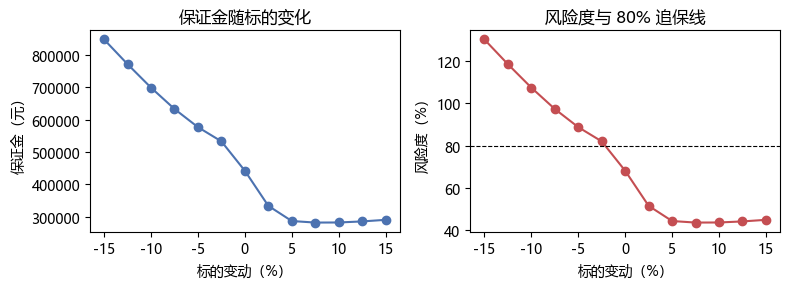

风险度超过 80% 触发追保/强平检查


In [4]:

R_MARGIN, R_FLOOR = 0.12, 0.07   # 教学示例参数，不对应任何交易所


def margin_short_option(F, K, premium, kind):
    otm = max(K - F, 0.0) * MULT if kind == "C" else max(F - K, 0.0) * MULT
    return premium * MULT + max(R_MARGIN * F * MULT - otm, R_FLOOR * F * MULT)


short_put = otm[(otm.K == 2950.0) & (otm.kind == "P")].iloc[0]
base_per_lot = margin_short_option(F0, 2950.0, float(short_put.mid), "P")
print("空", 120, "张 2950P：每张保证金", round(base_per_lot, 2),
      "合计", round(base_per_lot * 120, 2))

equity = 650000.0
for shock in [-0.10, -0.05, 0.0, 0.05, 0.10]:
    Fs = F0 * (1 + shock)
    prem = black76(Fs, 2950.0, T, float(short_put.iv_mid), r, "P")
    m = margin_short_option(Fs, 2950.0, float(prem), "P") * 120
    print(f"标的 {shock:+.0%}  F={Fs:7.1f}  期权价={float(prem):6.2f}  保证金={m:10.2f}  风险度={m / equity:.1%}")

shocks = np.linspace(-0.15, 0.15, 13)
margins, ratios = [], []
for s in shocks:
    Fs = F0 * (1 + s)
    prem = black76(Fs, 2950.0, T, float(short_put.iv_mid), r, "P")
    m = margin_short_option(Fs, 2950.0, float(prem), "P") * 120
    margins.append(m)
    ratios.append(m / equity)

fig, axes = plt.subplots(1, 2, figsize=(8, 3))
axes[0].plot(shocks * 100, margins, "o-", color="#4c72b0")
axes[0].set_xlabel("标的变动（%）")
axes[0].set_ylabel("保证金（元）")
axes[0].set_title("保证金随标的变化")
axes[1].plot(shocks * 100, np.array(ratios) * 100, "o-", color="#c44e52")
axes[1].axhline(80, color="black", linestyle="--", linewidth=0.8)
axes[1].set_xlabel("标的变动（%）")
axes[1].set_ylabel("风险度（%）")
axes[1].set_title("风险度与 80% 追保线")
plt.tight_layout()
plt.show()
print("风险度超过 80% 触发追保/强平检查")



**读数**：空 120 张 2950P，每张保证金 3,685.43，合计 442,251.96；以权益 65 万计，正常风险度 68.0%。标的跌 5% 到 2850 时，权利金涨到 138.70，保证金升到 576,834.74，风险度 88.7%，越过 80% 追保线；跌 10% 到 2700 时，保证金 698,741.40，风险度 107.5%，进入强平区间。反过来，标的涨 5%/10% 时风险度只有 44.2%/43.5%，因为空看跌越来越虚值、占用下降。**风险度对下跌高度不对称：同样 10% 的波动，向下是追保，向上只是释放保证金。**

**手算**：正常时 $0.12\times3000\times10=3600$，空看跌虚值额 $(3000-2950)\times10=500$，基准项取 $\max(3600-500,\ 2100)=3100$；权利金 $58.54\times10=585.4$，每张保证金 $585.4+3100=3685.4$，与代码一致。

**常见错误**：

1. 把教学参数当真实交易所参数。真实规则要看交易所公告和券商通知。
2. 只算单腿保证金，忽略组合净额与相关性。
3. 只算当前保证金，不做压力测试。极端行情下保证金可能跳升。
4. 风险度逼近 80% 才行动。追保和强平有执行时滞，应该提前减仓。

**停下来想一想**：为什么标的下跌时，空看跌的保证金可能反而上升？

<details><summary>对照你的思路</summary>

两个原因叠加：一是看跌期权权利金随标的下跌而上涨，保证金的“权利金项”变大；二是虚值额（对看跌是 $F-K$ 的正部）随下跌减少，公式里可抵扣的部分变小，保证金基准项上升。同时账户权益在下跌中缩水，风险度 = 保证金/权益，分子涨、分母跌，风险度上升更快。

</details>

---

## 5. 库存风险与做市 PnL

### 5.1 库存是怎么来的

做市商被动成交：客户买，你做空；客户卖，你做多。价差一笔笔赚，库存一点点积。库存的风险不是“账面浮亏”，而是：

- 方向暴露：净 Delta 偏离目标；
- 凸性暴露：Gamma 让 Delta 随价格变化；
- 波动率暴露：Vega 随隐波变化；
- 限额：单合约、单品种、总 Delta/Vega 上限。

### 5.2 PnL 拆分

$$\text{做市 PnL}=\underbrace{\sum \left|P_{\text{成交}}-P_{\text{中价}}\right|\times\text{数量}\times\text{乘数}}_{\text{价差捕获}}
+\underbrace{\Delta_{\text{库存}}\cdot\Delta F+\tfrac12\Gamma(\Delta F)^2+\text{Vega}\,\Delta\sigma}_{\text{库存盯市}}
-\text{费用}.$$

价差捕获是“确定的、小的”；库存盯市是“不确定的、可能很大”。做市管理的目标不是消灭库存风险，而是让库存风险与价差收入匹配。

### 5.3 代码：一段做市库存路径



成交笔数 74 期末库存(张) 4 价差捕获 1745.89
期末权益 1097.87 库存盯市部分 -648.02
最大库存 6 最大回撤 -521.54


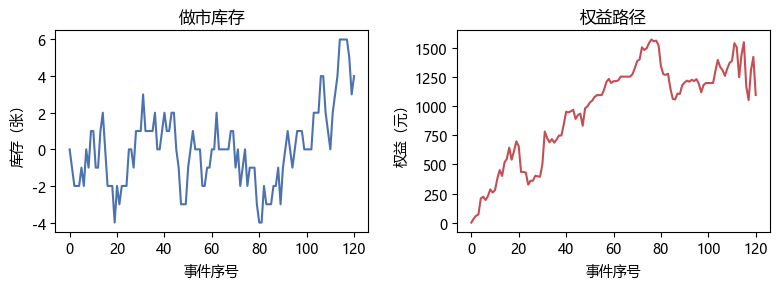

In [5]:

rng = np.random.default_rng(4601)
K_mm = 3000.0
iv_mm = 0.22
N = 120
F_path, q_path, eq_path = [F0], [0], [0.0]
cash, q, capture, fills = 0.0, 0, 0.0, 0
for _ in range(N):
    F = F_path[-1]
    mid = black76(F, K_mm, T, iv_mm, r)
    half = 0.004 * (1.0 + 2.0 * abs(np.log(K_mm / F)))
    if rng.random() < 0.6:
        side = 1 if rng.random() < 0.5 else -1
        qty = int(rng.integers(1, 3))
        px = black76(F, K_mm, T, iv_mm + side * half, r)
        cash += side * qty * px * MULT
        q -= side * qty
        capture += abs(px - mid) * qty * MULT
        fills += 1
    F_new = F * (1 + rng.normal(0.0, 0.004))
    F_path.append(F_new)
    q_path.append(q)
    eq_path.append(cash + q * black76(F_new, K_mm, T, iv_mm, r) * MULT)
print("成交笔数", fills, "期末库存(张)", q, "价差捕获", round(capture, 2))
print("期末权益", round(eq_path[-1], 2), "库存盯市部分", round(eq_path[-1] - capture, 2))
print("最大库存", max(abs(x) for x in q_path), "最大回撤",
      round(float(np.min(np.array(eq_path) - np.maximum.accumulate(eq_path))), 2))

fig, axes = plt.subplots(1, 2, figsize=(8, 3))
axes[0].plot(q_path, color="#4c72b0")
axes[0].set_xlabel("事件序号")
axes[0].set_ylabel("库存（张）")
axes[0].set_title("做市库存")
axes[1].plot(eq_path, color="#c44e52")
axes[1].set_xlabel("事件序号")
axes[1].set_ylabel("权益（元）")
axes[1].set_title("权益路径")
plt.tight_layout()
plt.show()



**读数**：120 个事件里成交 74 笔，最大库存 6 张（限额内），价差捕获 +1,745.89；但期末还留着 4 张库存，库存盯市 −648.02，净权益 +1,097.87，最大回撤 −521.54。**价差赚的是“确定的钱”，库存亏的是“不确定的钱”**：这段路径整体是赚的，但如果标的单边走出 3%—5%，同样的库存可能把多日价差一次吐回去。

**常见错误**：

1. 只统计价差捕获，不统计库存盯市。价差 +1,745、库存 −648，只看前者会高估做市收益。
2. 库存限额只在收盘检查。盘中被单边行情推着走，收盘时已经超标。
3. 用同一个隐含波动率报一整天。波动率变化时，库存的 Vega 会放大或缩小 PnL。

**停下来想一想**：如果期末库存方向相反（比如空 4 张而不是多 4 张），PnL 会怎么变？

<details><summary>对照你的思路</summary>

价差捕获不变，库存盯市符号反转，约为 +648；净 PnL 约 +2,394。但这不是“更好”，只是把敞口换了个方向：这段路径里库存最终是多头还是空头，取决于成交流与价格路径，不能事后挑方向评价做市。做市要比的是长期分布、限额和风险调整后收益。

</details>

---

## 6. 行权、指派与到期风险

### 6.1 到期结算

到期时，期权按结算规则处理：实值期权可能被行权/指派，虚值作废。做市商持有的空头实值期权被指派后，会变成期货（或现货）持仓，保证金要求随之变化。

### 6.2 指派后的账

- 空看跌被指派：按执行价 $K$ 买入标的（期货多头）；
- 空看涨被指派：按执行价 $K$ 卖出标的（期货空头）；
- 多头实值期权可以行权：看涨按 $K$ 买入，看跌按 $K$ 卖出；
- 指派是随机的，不是按开仓顺序；到期前就可能发生（美式）。

### 6.3 pin risk 与提前行权

标的价格恰好在执行价附近（pin）时，是否被指派不确定，做市商可能留下未预期的期货持仓；深度实值、时间价值很小时，对手方提前行权更划算，空头被提前指派的风险上升。

### 6.4 代码：到期指派与保证金变化



In [6]:

print("到期结算与指派（教学示例）")
for FT in [2900.0, 2940.0, 2950.0, 2960.0, 3000.0, 3050.0, 3100.0, 3150.0]:
    put_itm = max(2950.0 - FT, 0.0)
    call_itm = max(FT - 3050.0, 0.0)
    fut_pos = 0
    if put_itm > 0:
        fut_pos += 120          # 空看跌被指派：按 2950 买入期货
    if call_itm > 0:
        fut_pos += 200          # 多看涨行权：按 3050 买入期货
    margin = abs(fut_pos) * FT * MULT * R_MARGIN
    print(f"F_T={FT:6.1f}  空看跌内在={put_itm:5.1f}  多看涨内在={call_itm:5.1f}  "
          f"期货持仓={fut_pos:4d}手  期货保证金={margin:10.2f}")

T_short = 3 / 365
for K in [2950.0, 2900.0]:
    F_deep = 2550.0
    opt = black76(F_deep, K, T_short, 0.35, r, "P")
    intrinsic = max(K - F_deep, 0.0)
    print(f"F={F_deep} T={T_short * 365:.0f}天 空看跌 K={K}: "
          f"立即行权={intrinsic:.2f} 欧式模型价={opt:.2f} 差额={opt - intrinsic:+.2f}")
print("立即行权价值高于模型价 → 美式持有者提前行权更划算（未计费用）")


到期结算与指派（教学示例）
F_T=2900.0  空看跌内在= 50.0  多看涨内在=  0.0  期货持仓= 120手  期货保证金= 417600.00
F_T=2940.0  空看跌内在= 10.0  多看涨内在=  0.0  期货持仓= 120手  期货保证金= 423360.00
F_T=2950.0  空看跌内在=  0.0  多看涨内在=  0.0  期货持仓=   0手  期货保证金=      0.00
F_T=2960.0  空看跌内在=  0.0  多看涨内在=  0.0  期货持仓=   0手  期货保证金=      0.00
F_T=3000.0  空看跌内在=  0.0  多看涨内在=  0.0  期货持仓=   0手  期货保证金=      0.00
F_T=3050.0  空看跌内在=  0.0  多看涨内在=  0.0  期货持仓=   0手  期货保证金=      0.00
F_T=3100.0  空看跌内在=  0.0  多看涨内在= 50.0  期货持仓= 200手  期货保证金= 744000.00
F_T=3150.0  空看跌内在=  0.0  多看涨内在=100.0  期货持仓= 200手  期货保证金= 756000.00
F=2550.0 T=3天 空看跌 K=2950.0: 立即行权=400.00 欧式模型价=399.93 差额=-0.07
F=2550.0 T=3天 空看跌 K=2900.0: 立即行权=350.00 欧式模型价=349.94 差额=-0.06
立即行权价值高于模型价 → 美式持有者提前行权更划算（未计费用）



**读数**：结算价 2900 时，空 120 张 2950P 被指派，变成 120 手期货多头，按 12% 教学保证金率需 417,600 元；结算价 3100 时，多 200 张 3050C 行权，变成 200 手期货多头，保证金 744,000 元。2950–3050 之间两边的虚值期权都作废，期货持仓为 0。深度实值例子：标的 2550、剩 3 天，空看跌 K=2950 的立即行权价值 400.00，但欧式模型价只有 399.93，差额 −0.07——美式持有者提前行权有 0.07 的毛收益，扣掉手续费后可能不值得行权；但一旦收益超过成本，被提前指派的风险就会上升。

**常见错误**：

1. 只看到期日，不看提前指派。美式期权到期前就可能被行权。
2. 指派后只记期货持仓，不算保证金。行权不是终点，而是换了一个更大的风险头寸。
3. 忽略 pin risk。结算价贴执行价时，是否被指派取决于对手方行为，不能假设一定作废。
4. 用“虚值就安全”安慰自己。临近到期 gamma 很大，标的小动就会改变实虚值。

**停下来想一想**：为什么“深度实值 + 时间价值很小”时，提前行权风险会上升？

<details><summary>对照你的思路</summary>

提前行权相当于放弃剩余时间价值，换到立即的标的/期货头寸。时间价值很小时，放弃的成本小，而行权后可以马上获得头寸、降低保证金或对冲风险，收益可能超过成本。对卖方来说，这意味着“还没到期就可能被指派”，需要提前准备资金/保证金，或在流动性允许时买回期权平仓。

</details>

---

## 7. 做市风控清单

### 7.1 报价与库存

- [ ] 每个行权价的半价差是否随流动性和虚值程度调整？
- [ ] 库存偏斜是否随 Delta 变化，是否有上下限？
- [ ] 单合约/单品种/总 Delta、Vega、Gamma 限额是否定义？
- [ ] 报价有效期、撤单频率、被扫后的恢复逻辑是否明确？

### 7.2 保证金与资金

- [ ] 保证金模型是否与交易所/券商口径一致，多久复核一次？
- [ ] 压力测试是否覆盖 ±10%、±20% 与波动率跳升？
- [ ] 风险度阈值（预警/追保/强平）与动作是否明确？

### 7.3 到期与指派

- [ ] 到期日历、行权方式、结算价规则是否核对？
- [ ] 实值空头是否有提前平仓/移仓预案？
- [ ] pin risk 场景是否演练？
- [ ] 指派后的期货保证金与限额是否预留？

### 7.4 归因与复盘

- [ ] 每日 PnL 是否拆成价差捕获、库存盯市、费用、指派？
- [ ] 库存超限、报价被扫、保证金告急是否有记录？
- [ ] 参数（乘数、保证金率、行权规则）是否有版本和来源？

---

## 本章小结

### 一张表

| 环节 | 公式/做法 | 用途 |
|---|---|---|
| 中价 | 微笑 + 库存偏斜 | 报什么价 |
| 半价差 | $h_0(1+2|k|)$ | 流动性定价 |
| 反解 IV | Black–76 求根 | 价格→波动率 |
| Delta | $e^{-rT}\Phi(d_1)$ | 方向暴露 |
| Gamma | $e^{-rT}\phi(d_1)/(F\sigma\sqrt T)$ | 凸性暴露 |
| Vega | $e^{-rT}F\phi(d_1)\sqrt T$ | 波动率暴露 |
| 保证金 | 权利金 + max(比例×F−虚值, 保底×F) | 空头资金占用 |
| PnL | 价差捕获 + 库存盯市 − 费用 | 做市归因 |
| 指派 | 实值期权转期货持仓 | 到期风险 |

### 八句话

1. 做市赚的是价差，赔的是库存和尾部。
2. 报价 = 中价 + 半价差 + 库存偏斜。
3. 越虚值、流动性越差，价差越宽。
4. 只用 OTM 反解 IV，ITM 报价另作交易用。
5. Delta 中性不等于风险中性，Gamma/Vega 还在。
6. 保证金随价格变化，必须做压力测试。
7. 价差捕获是确定的，库存盯市是不确定的。
8. 到期指派不是终点，而是新的期货风险。

---

## 本章习题

**1.** 做市商的报价由哪四个要素构成？库存多头 Delta 时，报价应该往哪边偏？

**2.** 为什么构建波动率曲面时通常只用 OTM 期权反解 IV？ITM 报价还能用来做什么？

**3.** 多 200 张看涨（Delta 0.4151）、空 120 张看跌（Delta −0.3889），乘数 10。组合 Delta 敞口是多少？用期货对冲大约需要多少手？

**4.** 半价差 0.4 个波动率点、Vega 为 4.1 元/波动率点，一份期权的半价差金额约多少？乘数 10 时一手呢？

**5.** 用简化模型：$F=3000$、乘数 10、保证金率 12%、保底 7%、空看跌 K=2950、权利金 58.54 元。每张保证金多少？标的跌到 2700、权利金 258.28 时呢？

**6.** 一段做市路径：价差捕获 +1,745.89、库存盯市 −648.02、费用忽略。净 PnL 是多少？如果只看价差会高估多少？

**7.** 到期结算价 2940，空 120 张 2950P 被指派，变成多少手期货多头？按 12% 教学保证金率、乘数 10，期货保证金约多少？

**8.** 为什么做市商要特别关注 pin risk？到期前后可以做什么来降低风险？

<details><summary>参考答案</summary>

**1.** 四个要素：中价（模型/波动率）、半价差（流动性/竞争）、库存偏斜（库存方向）、数量与有效期（被扫风险）。库存多头 Delta 时报价整体下移，鼓励对手方买走、减少自己接买单。

**2.** OTM 期权 Vega 相对更大、报价更活跃、价差占比更合理；深度实值价格接近内在价值，Vega 小，反解误差被放大。ITM 报价可用于交易、套利、平价校验和指派判断，但一般不用于构建 IV 曲面。

**3.** Delta 敞口 $=200\times0.4151+(-120)\times(-0.3889)=83.02+46.67=129.69$（标的单位）；期货每手 1 单位标的，约需 130 手对冲。

**4.** 半价差金额 $=4.1\times0.4=1.64$ 元；乘数 10 时，一手半价差约 16.4 元。

**5.** 正常时虚值额 $=(3000-2950)\times10=500$，基准项 $\max(3600-500,\ 2100)=3100$；每张 $=58.54\times10+3100=3685.4$ 元。标的跌到 2700 时，看跌变成实值，虚值额 0，基准项 $\max(0.12\times2700\times10,\ 0.07\times2700\times10)=3240$；权利金 $258.28\times10=2582.8$，每张约 $2582.8+3240=5822.8$ 元，120 张合计 698,741 元。

**6.** 净 PnL $=1745.89-648.02=1097.87$；只看价差会把收益高估 648.02，约 59%。

**7.** 空 120 张 2950P 深度实值（2940 < 2950），被指派后按 2950 买入 120 手期货，变成 120 手多头；保证金 $=120\times2940\times10\times0.12=423{,}360$ 元。

**8.** pin risk 指结算价贴近执行价时，是否被指派不确定：实值一点点可能被行权，虚值一点点可能作废，做市商可能留下未预期的期货持仓和保证金。到期前后可以提前平仓/移仓、减少临近执行价的空头库存、预留期货保证金，并核对结算价与行权规则。

</details>

---

## 参考资料

- Hull, J. C. *Options, Futures, and Other Derivatives*（期权定价、Greeks、做市与对冲）。
- Black, F. (1976). The Pricing of Commodity Contracts（Black–76）。
- 交易所期权合约规则与保证金公告（以各交易所官方发布为准；本章参数均为教学示例）。
- 第 24–28、42、44 章（期权定价、Greeks、曲面、对冲、合约保证金、期权链）。
- advanced 05《实盘运维与逐笔对账》（成交与库存的事件化记录）。
